In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import utm
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
df = pd.read_parquet("../data/divar_clean.parquet")


<div dir="rtl" align="right">

## آماده‌سازی داده‌ها

ابتدا ردیف‌هایی که در ستون‌های مهم مقدار خالی دارند حذف می‌شوند.  
تعداد اتاق‌ها در داده به صورت متن است و عددی نیستند، به همین دلیل با یک دیکشنری به عدد **تبدیل** شده‌اند (`بدون اتاق` برابر ۰ و `پنج یا بیشتر` برابر ۵).  
سپس مختصات جغرافیایی با کتابخانه `utm` به **UTM** تبدیل شده و در ستون‌های `utm_x` و `utm_y` ذخیره شده است.

</div>

In [3]:
features = ["location_latitude", "location_longitude", "price_value", "building_size", "rooms_count"]

df = pd.read_parquet("../data/divar_clean.parquet", columns=features)
print(df.shape)

(997409, 5)


In [4]:
df = df.dropna().copy()
print(df.shape)
print(df.isna().sum().sum())

(277711, 5)
0


In [5]:
utm_x, utm_y = [], []
for lat, lon in zip(df["location_latitude"], df["location_longitude"]):
    x, y, _, _ = utm.from_latlon(lat, lon, force_zone_number=39)
    utm_x.append(x)
    utm_y.append(y)
df["utm_x"] = utm_x
df["utm_y"] = utm_y
print(df.shape)

(277711, 7)


<div dir="rtl" align="right">

## خوشه‌بندی با KMeans

در این بخش ابتدا داده‌ها با `StandardScaler` **استاندارد** می‌شوند.  
سپس **KMeans** با **۱۰ خوشه** و **۱۰ بار** شروع با نقطه تصادفی (`n_init=10`) اجرا می‌شود.  
خروجی `labels` برای هر ردیف داده یک عدد بین ۰ تا ۹ است که نشان می‌دهد آن ردیف در کدام خوشه قرار دارد.  
در پایان **مرکز خوشه‌ها** به مقیاس اصلی برگردانده می‌شود تا روی نمودار UTM نمایش داده شود.

</div>

In [6]:
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

kmeans = KMeans(n_clusters=10, n_init=10, random_state=44)
labels = kmeans.fit_predict(X_scaled)
df["cluster"] = labels
print(df["cluster"].value_counts().sort_index())

(277711, 5)
cluster
0    94143
1    21965
2    38308
3        2
4      330
5    39961
6        1
7       20
8    57414
9    25567
Name: count, dtype: int64


In [7]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

center_utm_x, center_utm_y = [], []
for lat, lon in zip(centers[:, 0], centers[:, 1]):
    x, y, _, _ = utm.from_latlon(lat, lon, force_zone_number=39)
    center_utm_x.append(x)
    center_utm_y.append(y)

<div dir="rtl" align="right">

## نمودار خوشه‌ها

در این نمودار هر نقطه یک ملک است که با توجه به خوشه‌اش رنگ شده و **مرکز هر خوشه** با علامت `X` مشکی نمایش داده شده است.

</div>

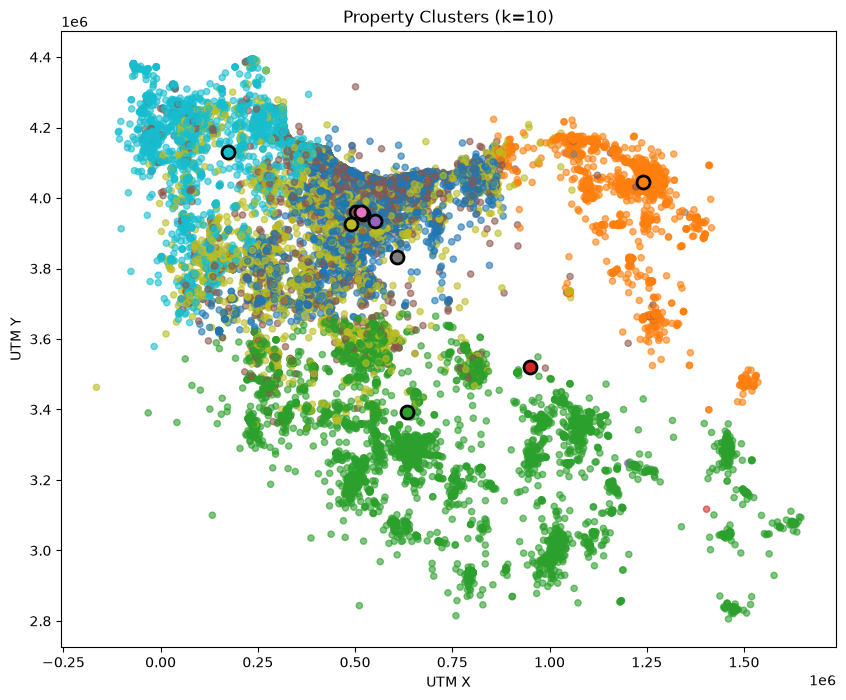

In [17]:
colors = plt.cm.tab10.colors

plt.figure(figsize=(10, 8))
plt.scatter(df["utm_x"], df["utm_y"], c=df["cluster"], cmap="tab10", vmin=0, vmax=9, s=20, alpha=0.6)

for i in range(10):
    plt.scatter(center_utm_x[i], center_utm_y[i], color=colors[i], marker=".", s=350, edgecolors="black", linewidths=2, zorder=5)

plt.xlabel("UTM X")
plt.ylabel("UTM Y")
plt.title("Property Clusters (k=10)")
plt.show()

In [9]:
print(df.groupby("cluster")[features].mean())

         location_latitude  location_longitude   price_value  building_size  \
cluster                                                                       
0                35.736992           51.233308  5.053796e+09   1.228017e+02   
1                36.268452           59.231199  4.638498e+09   2.441202e+02   
2                30.662366           52.401003  5.259089e+09   3.371024e+02   
3                31.731148           55.737448  2.750000e+11   4.500000e+06   
4                35.543055           51.574751  4.097064e+11   8.628864e+03   
5                35.798870           51.018476  1.542780e+10   3.465902e+02   
6                35.793968           51.163807  1.500000e+13   1.000000e+06   
7                34.627965           52.185554  5.833000e+10   1.081400e+06   
8                35.471690           50.870133  3.952983e+09   4.171916e+02   
9                37.256080           47.321448  3.888828e+09   2.095035e+02   

         rooms_count  
cluster               
0    

In [10]:
wcss = []
results = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=44)
    lab = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)

    if k >= 2:
        sil = silhouette_score(X_scaled, lab, sample_size=10000, random_state=44)
        db = davies_bouldin_score(X_scaled, lab)
        ch = calinski_harabasz_score(X_scaled, lab)
        results.append([k, sil, db, ch])

table = pd.DataFrame(results, columns=["K", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"])
print(table)

    K  Silhouette  Davies-Bouldin  Calinski-Harabasz
0   2    0.415492        1.152854       50960.720594
1   3    0.417185        1.017612       55443.056194
2   4    0.417185        0.721031       61878.703455
3   5    0.471068        0.681093       74719.005815
4   6    0.406468        0.695486       85276.466609
5   7    0.406468        0.611059       88598.382813
6   8    0.412128        0.671788       93987.351128
7   9    0.431645        0.639626       94403.476503
8  10    0.439364        0.629892       97249.853865


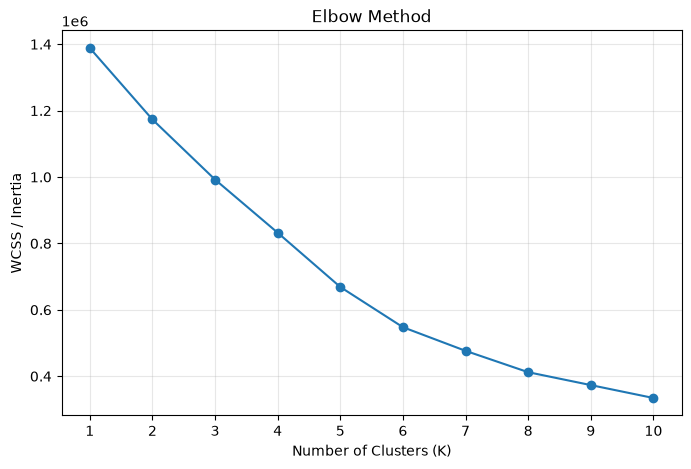

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil = silhouette_score(X_scaled, labels)
db = davies_bouldin_score(X_scaled, labels)
ch = calinski_harabasz_score(X_scaled, labels)

print("Silhouette Score:", sil)
print("Davies-Bouldin Index:", db)
print("Calinski-Harabasz Index:", ch)

Silhouette Score: 0.4450934057977279
Davies-Bouldin Index: 0.6298921953952537
Calinski-Harabasz Index: 97249.85386495414


<div dir="rtl" align="right">

## نتیجه معیارهای ارزیابی برای ۱۰ خوشه

- **Silhouette Score:** `0.48854769831606154`
- **Davies-Bouldin Index:** `0.7285172275844325`
- **Calinski-Harabasz Index:** `133710.6966063492`

</div>

In [ ]:
results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    results.append([k, sil, db, ch])

for row in results:
    print(row)

KeyboardInterrupt: 

<div dir="rtl" align="right">

## مقایسه معیارها برای تعداد خوشه‌های مختلف

هر ردیف از خروجی زیر به صورت
`[K, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index]`
است و نتیجه‌ی **KMeans** را برای هر مقدار `K` نشان می‌دهد.

</div>

<div dir="rtl" align="right">
[K, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index]

[2, 0.9779510409595203, 0.2569208120406292, 57975.02361085802]

[3, 0.41975427209610966, 0.8417677960005018, 68734.35081746752]

[4, 0.4240892232221648, 0.7205113735613367, 91118.63991786462]

[5, 0.4791324147836299, 0.681273557660147, 109505.77522425045]

[6, 0.42554047092165154, 0.6868054621139477, 128355.62252939772]

[7, 0.4397088891573724, 0.7286977943324453, 132127.03945575812]

[8, 0.46457733729416184, 0.6611260839774562, 131005.19794752896]

[9, 0.4825715459272108, 0.728682948371841, 133199.87261835937]

[10, 0.4885240025883436, 0.7277330143652969, 133710.42901132346]
</div>

<div dir="rtl" align="right">

## نمودار دقت خوشه‌ها (Elbow)

در این بخش مقدار **WCSS** برای `K` از ۱ تا ۱۰ محاسبه شده و در نمودار رسم می‌شود تا با **روش آرنج** بهترین تعداد خوشه انتخاب شود.

</div>

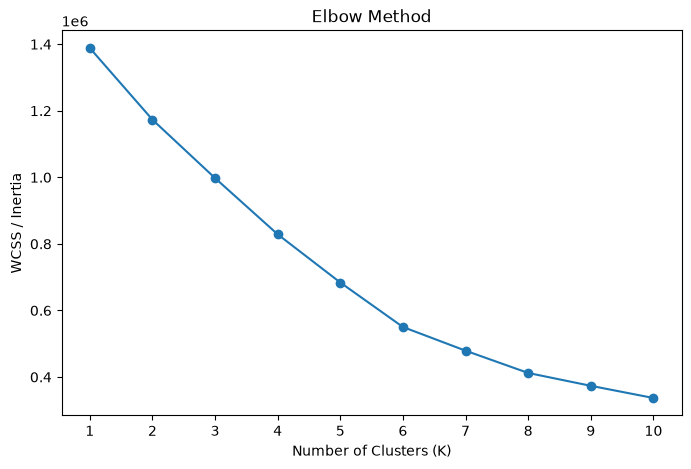

In [13]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()